# Import

In [1]:
# Data Handling
import numpy as np
import pandas as pd
from pathlib import Path

# Image Processing
from PIL import Image

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split
from sklearn.model_selection import train_test_split

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Neural Network
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)

# Optimizer
from tensorflow.keras.optimizers import Adam

# Callbacks
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Random Seed
tf.keras.utils.set_random_seed(42)

# Reading Data

In [2]:
folder = Path("UTKFace")

data = []

for file in folder.glob("*.jpg"):
    try:
        age, gender, race = map(int, file.stem.split("_")[:3])

        data.append({
            "image_path": str(file),
            "age": age,
            "gender": gender,
            "race": race
        })
    except ValueError:
        continue

df = pd.DataFrame(data)

print(df.shape)
df.head()

(23705, 4)


,image_path,age,gender,race
0,UTKFace\100_0_0_20170112213500903.jpg.chip.jpg,100,0,0
1,UTKFace\100_0_0_20170112215240346.jpg.chip.jpg,100,0,0
2,UTKFace\100_1_0_20170110183726390.jpg.chip.jpg,100,1,0
3,UTKFace\100_1_0_20170112213001988.jpg.chip.jpg,100,1,0
4,UTKFace\100_1_0_20170112213303693.jpg.chip.jpg,100,1,0


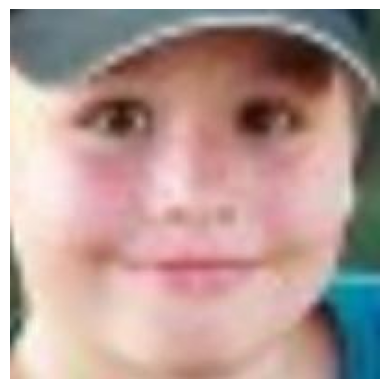

In [17]:
img = Image.open(df["image_path"].iloc[29])

plt.imshow(img)
plt.axis("off")
plt.show()

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23705 entries, 0 to 23704
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image_path  23705 non-null  str  
 1   age         23705 non-null  int64
 2   gender      23705 non-null  int64
 3   race        23705 non-null  int64
dtypes: int64(3), str(1)
memory usage: 1.7 MB


In [6]:
df.describe()

,age,gender,race
count,23705.000000,23705.000000,23705.000000
mean,33.300907,0.477283,1.269226
std,19.885708,0.499494,1.345638
min,1.000000,0.000000,0.000000
25%,23.000000,0.000000,0.000000
50%,29.000000,0.000000,1.000000
75%,45.000000,1.000000,2.000000
max,116.000000,1.000000,4.000000


In [7]:
df.isnull().sum()

image_path    0
age           0
gender        0
race          0
dtype: int64

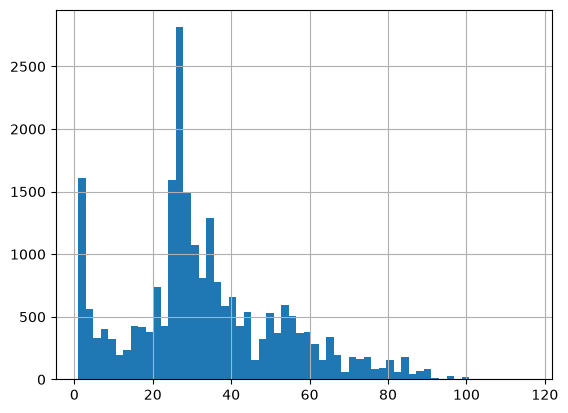

In [8]:
df['age'].hist(bins=60);

# Splitting Data

In [9]:
X = df["image_path"]
y = df["age"]

In [10]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42)

# Preprocessing

In [22]:
def load_image(path):
    with Image.open(path) as img:
        img = img.convert("L")
        img = img.resize((32, 32))
        return np.array(img, dtype=np.float32) / 255.0

In [23]:
X_train_img = np.array([load_image(path) for path in X_train])

X_val_img = np.array([load_image(path) for path in X_val])

X_test_img = np.array([load_image(path) for path in X_test])

# NN

## Base Model

In [24]:
baseline_model = Sequential([
    Input(shape=X_train_img.shape[1:]),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1)
])

baseline_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mae',
    metrics=['mae']
)

baseline_history = baseline_model.fit(X_train_img, y_train, validation_data=(X_val_img, y_val), epochs=5, batch_size=16)

Epoch 1/5
949/949 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 15.9134 - mae: 15.9134 - val_loss: 14.6369 - val_mae: 14.6369
Epoch 2/5
949/949 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 13.8232 - mae: 13.8232 - val_loss: 13.9161 - val_mae: 13.9161
Epoch 3/5
949/949 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 12.8036 - mae: 12.8036 - val_loss: 12.7910 - val_mae: 12.7910
Epoch 4/5
949/949 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 12.2672 - mae: 12.2672 - val_loss: 12.2006 - val_mae: 12.2006
Epoch 5/5
949/949 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 11.9006 - mae: 11.9006 - val_loss: 12.2516 - val_mae: 12.2516


## Advanced Model

In [32]:
model = Sequential([
    Input(shape=X_train_img.shape[1:]),
    Flatten(),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mae',
    metrics=['mae']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=0.00001
)

history = model.fit(X_train_img, y_train, validation_data=(X_val_img, y_val), epochs=50, batch_size=16, callbacks=[early_stop, reduce_lr])

Epoch 1/50
949/949 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 15.4144 - mae: 15.4144 - val_loss: 13.0114 - val_mae: 13.0114 - learning_rate: 0.0010
Epoch 2/50
949/949 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 12.8418 - mae: 12.8418 - val_loss: 12.0524 - val_mae: 12.0524 - learning_rate: 0.0010
Epoch 3/50
949/949 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 11.9141 - mae: 11.9141 - val_loss: 10.8072 - val_mae: 10.8072 - learning_rate: 0.0010
Epoch 4/50
949/949 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 11.2253 - mae: 11.2253 - val_loss: 10.4578 - val_mae: 10.4578 - learning_rate: 0.0010
Epoch 5/50
949/949 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 11.1965 - mae: 11.1965 - val_loss: 10.1469 - val_mae: 10.1469 - learning_rate: 0.0010
Epoch 6/50
949/949 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - loss: 10.6117 - mae: 10.6117 - val_loss: 10.6843 - val_mae: 10.6843 - learning_rate: 0.0010
Epoch 7/50
949/949 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 10.2675 - mae: 10.2675 - val_loss: 10.2193 - val_m

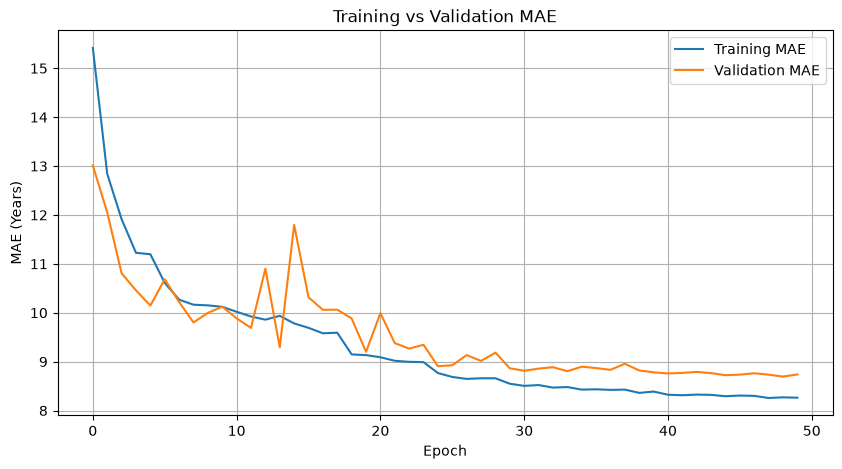

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')

plt.xlabel('Epoch')
plt.ylabel('MAE (Years)')
plt.title('Training vs Validation MAE')
plt.legend()
plt.grid()
plt.show()

# Evaluating

In [34]:
test_loss, test_mae = model.evaluate(X_test_img, y_test)

print("Test MAE:", test_mae)

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.6412 - mae: 8.6412
Test MAE: 8.641213417053223


In [35]:
y_pred = model.predict(X_test_img).flatten()

results = pd.DataFrame({
    'Actual Age': y_test,
    'Predicted Age': y_pred.round(1)
})

results['Error'] = abs(results['Actual Age'] - results['Predicted Age'])

results.head(10)

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


,Actual Age,Predicted Age,Error
17814,4,27.600000,23.600000
15080,3,1.200000,1.800000
22829,82,51.700001,30.299999
16074,42,30.299999,11.700001
8972,28,29.100000,1.100000
19252,55,35.599998,19.400002
14324,37,27.400000,9.600000
19246,55,37.900002,17.099998
13340,35,48.299999,13.299999
21041,64,32.599998,31.400002


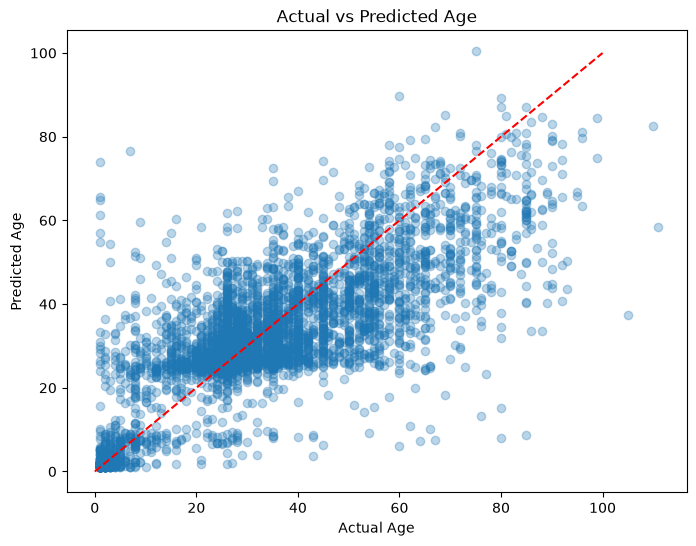

In [36]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot([0, 100], [0, 100], 'r--')

plt.xlabel('Actual Age')
plt.ylabel('Predicted Age')
plt.title('Actual vs Predicted Age')
plt.show()

***We see that the model predicts 1 and 26 years old most of the times and that's because of the data we have***

# Saving the Model

In [37]:
model.save("age_model.keras")